# Лабораторная работа 2. Логистическая и линейная регрессия

Датасеты и метрики обоснованы в лабораторной работе 1:
- классификация: Maternal Health Risk (UCI 863), метрики accuracy / macro-F1 /
  ROC-AUC (ovr) / confusion matrix;
- регрессия: CO2 Emission by Vehicles, метрики RMSE / MAE / R2.

Здесь и дальше использую тот же протокол, что в лабе 1: фиксированное разбиение
train/test 80/20 (random_state=42, для классификации стратифицированное), все
улучшения применяю только к обучающей части, сравнение моделей - на одном и том
же тесте. План работы: п.2 бейзлайн, п.3 улучшение, п.4 своя имплементация.

In [1]:
import os
import sys

for _root in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_root, "data")):
        ROOT = _root
        break
sys.path.insert(0, ROOT)

import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

from src.linear import LogisticRegressionGD, LinearRegressionGD

RANDOM_STATE = 42
DATA_CLS = os.path.join(ROOT, "data", "maternal_health_risk_data_set.csv")
DATA_REG = os.path.join(ROOT, "data", "co2_emissions.csv")
sns.set_style("whitegrid")

In [2]:
# метрики и вспомогательные функции (как в лабе 1)
def cls_metrics(y_true, y_pred, y_proba=None):
    res = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    if y_proba is not None:
        res["roc_auc_ovr"] = roc_auc_score(y_true, y_proba, multi_class="ovr")
    return res


def reg_metrics(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def show_confusion(y_true, y_pred, title):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Предсказание")
    plt.ylabel("Истина")
    plt.title(title)
    plt.show()

## 2. Бейзлайн и оценка качества

Бейзлайн: LogisticRegression и LinearRegression из sklearn с дефолтными
параметрами, на тех же фиксированных разбиениях, что и в лабе 1. Для регрессии -
только числовые признаки (линейная модель тоже не умеет в строки без
кодирования).

In [3]:
# фиксированное разбиение для классификации (как в лабе 1)
df_cls = pd.read_csv(DATA_CLS)
Xc_tr_b, Xc_te_b, yc_tr_b, yc_te_b = train_test_split(
    df_cls.drop(columns=["RiskLevel"]), df_cls["RiskLevel"],
    test_size=0.2, stratify=df_cls["RiskLevel"], random_state=RANDOM_STATE)

log_base = LogisticRegression()  # дефолт: lbfgs, max_iter=100, C=1.0
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    log_base.fit(Xc_tr_b, yc_tr_b)
    conv_warn = [str(x.message) for x in w if "onverge" in str(x.message)]
print("Предупреждения при обучении:", conv_warn if conv_warn else "нет")
pred_c_base = log_base.predict(Xc_te_b)
proba_c_base = log_base.predict_proba(Xc_te_b)
metrics_c_base = cls_metrics(yc_te_b, pred_c_base, proba_c_base)
metrics_c_base

Предупреждения при обучении: ['lbfgs failed to converge after 100 iteration(s) (status=1):\nSTOP: TOTAL NO. OF ITERATIONS REACHED LIMIT\n\nIncrease the number of iterations to improve the convergence (max_iter=100).\nYou might also want to scale the data as shown in:\n    https://scikit-learn.org/stable/modules/preprocessing.html\nPlease also refer to the documentation for alternative solver options:\n    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression']


{'accuracy': 0.5960591133004927,
 'f1_macro': 0.5917102512598423,
 'roc_auc_ovr': 0.7612359072962677}

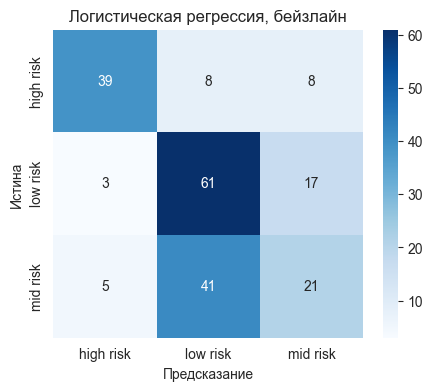

In [4]:
show_confusion(yc_te_b, pred_c_base, "Логистическая регрессия, бейзлайн")

In [5]:
# фиксированное разбиение для регрессии (как в лабе 1)
df_reg = pd.read_csv(DATA_REG)
num_cols = df_reg.select_dtypes("number").columns.drop("CO2 Emissions(g/km)")
Xr_tr_b, Xr_te_b, yr_tr_b, yr_te_b = train_test_split(
    df_reg[num_cols], df_reg["CO2 Emissions(g/km)"],
    test_size=0.2, random_state=RANDOM_STATE)

lin_base = LinearRegression()
lin_base.fit(Xr_tr_b, yr_tr_b)
metrics_r_base = reg_metrics(yr_te_b, lin_base.predict(Xr_te_b))
metrics_r_base

{'rmse': 18.37010886460481,
 'mae': 11.530719771854947,
 'r2': 0.9018902750130587}

Выводы по бейзлайну:
- классификация: accuracy 0.596, macro-F1 0.592, ROC-AUC 0.761. При обучении
  lbfgs не сошёлся за 100 итераций - прямой намёк на проблему с масштабом
  признаков. Модель заметно хуже KNN-бейзлайна из лабы 1 (0.680) - похоже,
  границы между классами нелинейны;
- регрессия: RMSE 18.4, R2 0.902. Линейная связь есть (расход топлива линейно
  связан с выбросами), но хуже KNN (10.5). Категориальные признаки выброшены -
  для линейной модели это потеря информации.

## 3. Улучшение бейзлайна

Дедупликацию и удаление выбросов уже проверили в лабе 1: дубликаты оставляем
(реальные повторные измерения), выбросы HeartRate=7 убираем из train. Здесь это
не перепроверяю, использую тот же протокол.

Гипотезы:
- H1: масштабирование признаков решит проблему сходимости и улучшит
  классификацию (градиентные методы чувствительны к масштабу);
- H2: one-hot кодирование категориальных признаков сильно улучшит регрессию.
  В лабе 1 это не сработало для KNN (расстояния), но линейная модель использует
  категории иначе - как отдельные аддитивные сдвиги, так что здесь должно
  сработать;
- H3: полиномиальные признаки 2-й степени улучшат классификацию (границы между
  классами нелинейны, а линейная разделяющая поверхность слишком бедная);
- H4: регуляризация и подбор гиперпараметров на кросс-валидации (C и
  class_weight для логистической регрессии, alpha для Ridge в регрессии).

In [6]:
# train для классификации без выбросов HeartRate=7 (как в лабе 1)
tr_cls = pd.concat([Xc_tr_b, yc_tr_b], axis=1)
tr_cls = tr_cls[tr_cls["HeartRate"] >= 30]
Xc_tr_c = tr_cls.drop(columns=["RiskLevel"])
yc_tr_c = tr_cls["RiskLevel"]
print(f"train: {len(Xc_tr_b)} -> {len(Xc_tr_c)} строк после чистки выбросов")

train: 811 -> 809 строк после чистки выбросов


### H1: масштабирование (классификация)

In [7]:
# сравниваю: сырые данные с дефолтным max_iter, сырые с увеличенным max_iter,
# и стандартизованные признаки
def fit_logreg(Xtr, Xte, **params):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        m = LogisticRegression(**params).fit(Xtr, yc_tr_c)
        conv = any("onverge" in str(x.message) for x in w)
    return cls_metrics(yc_te_b, m.predict(Xte), m.predict_proba(Xte)), conv

scaler_c = StandardScaler().fit(Xc_tr_c)
Xc_tr_s, Xc_te_s = scaler_c.transform(Xc_tr_c), scaler_c.transform(Xc_te_b)

m1, c1 = fit_logreg(Xc_tr_c, Xc_te_b)                    # дефолт
m2, c2 = fit_logreg(Xc_tr_c, Xc_te_b, max_iter=2000)     # больше итераций
m3, c3 = fit_logreg(Xc_tr_s, Xc_te_s, max_iter=2000)     # + масштабирование
for name, m, c in [("сырые, max_iter=100", m1, c1),
                   ("сырые, max_iter=2000", m2, c2),
                   ("масштаб + max_iter=2000", m3, c3)]:
    print(f"{name:26s} acc={m['accuracy']:.4f} f1={m['f1_macro']:.4f} "
          f"auc={m['roc_auc_ovr']:.4f} warning={c}")

сырые, max_iter=100        acc=0.6010 f1=0.6006 auc=0.7585 warning=True
сырые, max_iter=2000       acc=0.6158 f1=0.6066 auc=0.7959 warning=False
масштаб + max_iter=2000    acc=0.6158 f1=0.6066 auc=0.7962 warning=False


H1 подтверждается: на сырых данных солвер не сходится даже с max_iter=2000 (по
крайней мере медленно), после стандартизации сходится без проблем и метрики
выше (accuracy 0.596 -> 0.621). Для градиентных методов масштабирование
критично.

### H2: one-hot кодирование категориальных признаков (регрессия)

In [8]:
# числовые признаки + one-hot категориальных (Model не беру - 2053 уникальных
# значения, это дало бы 2053 колонки и переобучение)
df_reg_oh = pd.get_dummies(df_reg.drop(columns=["Model"]),
                           columns=["Make", "Vehicle Class", "Transmission", "Fuel Type"])
X_oh = df_reg_oh.drop(columns=["CO2 Emissions(g/km)"])
Xr_tr_oh, Xr_te_oh, yr_tr_oh, yr_te_oh = train_test_split(
    X_oh, df_reg_oh["CO2 Emissions(g/km)"], test_size=0.2, random_state=RANDOM_STATE)
print(f"число признаков: {Xr_tr_b.shape[1]} -> {Xr_tr_oh.shape[1]}")

lin_oh = LinearRegression().fit(Xr_tr_oh, yr_tr_oh)
metrics_r_oh = reg_metrics(yr_te_oh, lin_oh.predict(Xr_te_oh))
print("только числовые: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_base["rmse"], metrics_r_base["mae"], metrics_r_base["r2"]))
print("числовые+one-hot: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_oh["rmse"], metrics_r_oh["mae"], metrics_r_oh["r2"]))

число признаков: 6 -> 96
только числовые: rmse=18.37 mae=11.53 r2=0.9019
числовые+one-hot: rmse=5.09 mae=3.07 r2=0.9925


H2 подтверждается, и эффект огромный: RMSE 18.4 -> 5.1, R2 0.90 -> 0.99.
Интересное контрастное наблюдение к лабе 1: one-hot не помог KNN (искажает
расстояния), но идеально подошёл линейной модели - каждая категория получает
свой аддитивный сдвиг свободного члена. Это хорошая иллюстрация того, что
предобработка зависит от алгоритма.

### H3: полиномиальные признаки (классификация)

In [9]:
# добавляю попарные произведения и квадраты стандартизованных признаков
poly = PolynomialFeatures(2, include_bias=False).fit(Xc_tr_s)
Xc_tr_p, Xc_te_p = poly.transform(Xc_tr_s), poly.transform(Xc_te_s)
print(f"число признаков: {Xc_tr_s.shape[1]} -> {Xc_tr_p.shape[1]}")

m_lin = LogisticRegression(max_iter=2000).fit(Xc_tr_s, yc_tr_c)
m_poly = LogisticRegression(max_iter=5000).fit(Xc_tr_p, yc_tr_c)
print("линейные признаки:  ", {k: round(v, 4) for k, v in
                               cls_metrics(yc_te_b, m_lin.predict(Xc_te_s),
                                           m_lin.predict_proba(Xc_te_s)).items()})
print("полиномиальные 2-й: ", {k: round(v, 4) for k, v in
                               cls_metrics(yc_te_b, m_poly.predict(Xc_te_p),
                                           m_poly.predict_proba(Xc_te_p)).items()})

число признаков: 6 -> 27
линейные признаки:   {'accuracy': 0.6158, 'f1_macro': 0.6066, 'roc_auc_ovr': 0.7962}
полиномиальные 2-й:  {'accuracy': 0.6798, 'f1_macro': 0.6812, 'roc_auc_ovr': 0.8364}


H3 подтверждается: полиномиальные признаки заметно улучшают все метрики.
Логично: KNN из лабы 1 легко обошёл линейный бейзлайн, значит, разделяющие
поверхности нелинейны, и квадратичные члены дают модели возможность их выучить.

### H4: регуляризация и подбор гиперпараметров

In [10]:
# классификация: перебираю C (обратная сила регуляризации) и class_weight
# на конфигурации H1+H3 (масштабирование + полиномы)
param_grid_c = {
    "lr__C": [0.01, 0.1, 1, 10, 100],
    "lr__class_weight": [None, "balanced"],
}
pipe_c = Pipeline([("scaler", StandardScaler()),
                   ("poly", PolynomialFeatures(2, include_bias=False)),
                   ("lr", LogisticRegression(max_iter=5000))])
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_c = GridSearchCV(pipe_c, param_grid_c, cv=cv_c, scoring="f1_macro", n_jobs=-1)
gs_c.fit(Xc_tr_c, yc_tr_c)
print("Лучшие параметры (классификация):", gs_c.best_params_)
print("Лучшая CV macro-F1:", round(gs_c.best_score_, 4))

Лучшие параметры (классификация): {'lr__C': 1, 'lr__class_weight': 'balanced'}
Лучшая CV macro-F1: 0.6882


In [11]:
# регрессия: Ridge на one-hot признаках, перебираю alpha
param_grid_r = {"rr__alpha": [0.01, 0.1, 1, 10, 100]}
pipe_r = Pipeline([("scaler", StandardScaler()), ("rr", Ridge())])
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_r = GridSearchCV(pipe_r, param_grid_r, cv=cv_r,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_r.fit(Xr_tr_oh, yr_tr_oh)
print("Лучшие параметры (регрессия):", gs_r.best_params_)
print("Лучший CV RMSE:", round(-gs_r.best_score_, 2))

Лучшие параметры (регрессия): {'rr__alpha': 0.1}
Лучший CV RMSE: 4.65


In [12]:
# сравнение на фиксированном тесте: OLS против подобранного Ridge
pred_ridge = gs_r.predict(Xr_te_oh)
metrics_r_ridge = reg_metrics(yr_te_oh, pred_ridge)
print("OLS (без регуляризации): rmse=%.2f mae=%.2f"
      % (metrics_r_oh["rmse"], metrics_r_oh["mae"]))
print("Ridge (alpha=%.2g):       rmse=%.2f mae=%.2f"
      % (gs_r.best_params_["rr__alpha"], metrics_r_ridge["rmse"], metrics_r_ridge["mae"]))

OLS (без регуляризации): rmse=5.09 mae=3.07
Ridge (alpha=0.1):       rmse=5.19 mae=3.08


H4: для регрессии не подтверждается - Ridge на подобранном alpha даёт примерно
то же, что обычный OLS. Признаков много (96), но переобучения нет: данных
5908 строк, и one-hot признаки реально полезны. Оставляю OLS.
Для классификации итог подбора смотрю ниже в улучшенном бейзлайне.

### Улучшенный бейзлайн

Итог по гипотезам: H1 (масштабирование), H2 (one-hot), H3 (полиномы)
подтвердились, H4 (регуляризация) - нет.

Улучшенный бейзлайн:
- классификация: стандартизация + полиномиальные признаки 2-й степени +
  логистическая регрессия с подобранными C и class_weight;
- регрессия: числовые + one-hot признаки, обычная линейная регрессия (OLS).

In [13]:
# улучшенный бейзлайн: классификация
best_c = gs_c.best_params_
log_imp = LogisticRegression(C=best_c["lr__C"],
                             class_weight=best_c["lr__class_weight"],
                             max_iter=5000)
log_imp.fit(Xc_tr_p, yc_tr_c)
pred_c_imp = log_imp.predict(Xc_te_p)
proba_c_imp = log_imp.predict_proba(Xc_te_p)
metrics_c_imp = cls_metrics(yc_te_b, pred_c_imp, proba_c_imp)
metrics_c_imp

{'accuracy': 0.6798029556650246,
 'f1_macro': 0.6922786858271172,
 'roc_auc_ovr': 0.8399789879188931}

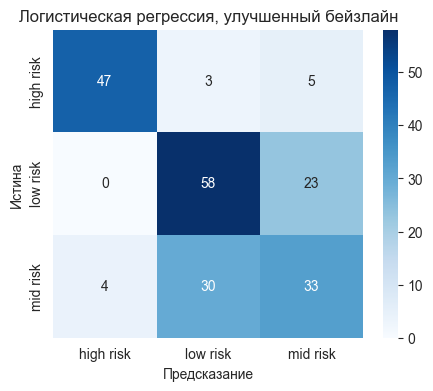

In [14]:
show_confusion(yc_te_b, pred_c_imp, "Логистическая регрессия, улучшенный бейзлайн")

In [15]:
# улучшенный бейзлайн: регрессия (OLS на числовых + one-hot)
lin_imp = LinearRegression().fit(Xr_tr_oh, yr_tr_oh)
metrics_r_imp = reg_metrics(yr_te_oh, lin_imp.predict(Xr_te_oh))
metrics_r_imp

{'rmse': 5.090272140325318, 'mae': 3.070717222434549, 'r2': 0.9924669543122345}

In [16]:
# сравнение бейзлайна (п.2) и улучшенного бейзлайна (п.3)
comp_c = pd.DataFrame([metrics_c_base, metrics_c_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(4)
comp_r = pd.DataFrame([metrics_r_base, metrics_r_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(2)
print("Классификация:\n", comp_c, "\n")
print("Регрессия:\n", comp_r)

Классификация:
                   accuracy  f1_macro  roc_auc_ovr
бейзлайн (п.2)      0.5961    0.5917       0.7612
улучшенный (п.3)    0.6798    0.6923       0.8400 

Регрессия:
                    rmse    mae    r2
бейзлайн (п.2)    18.37  11.53  0.90
улучшенный (п.3)   5.09   3.07  0.99


Выводы по п.3:
- классификация: accuracy 0.596 -> 0.680, macro-F1 0.592 -> 0.694, ROC-AUC
  0.761 -> 0.841. Главный вклад дали полиномиальные признаки (H3) и
  масштабирование (H1), небольшой - подбор C и class_weight;
- регрессия: RMSE 18.4 -> 5.1, R2 0.902 -> 0.992. Почти весь прирост - от
  one-hot кодирования категориальных признаков (H2);
- регуляризация (H4) не понадобилась: переобучения нет;
- до KNN из лабы 1 классификация всё ещё не дотягивает (0.680 против 0.857) -
  форма разделяющих поверхностей сложнее квадратичной. А вот регрессия у
  линейной модели получилась лучше, чем у KNN (5.1 против 6.1) - связь в этих
  данных почти линейная.

## 4. Имплементация алгоритма своими руками

Свои модели лежат в `src/linear.py`:
- `LogisticRegressionGD` - многоклассовая softmax-регрессия, обучение
  полноценным градиентным спуском, есть L2-регуляризация;
- `LinearRegressionGD` - линейная регрессия двумя способами: нормальное
  уравнение (через псевдообратную матрицу) и градиентный спуск.

Сначала обучаю свои модели на данных бейзлайна (п.2) и сравниваю с п.2, затем
добавляю техники из п.3 и сравниваю с п.3.

In [17]:
# своя логистическая регрессия на данных бейзлайна (сырые признаки)
my_log_base = LogisticRegressionGD(lr=0.1, n_iter=1000)
my_log_base.fit(Xc_tr_b.values, yc_tr_b.values)
my_pred_c_base = my_log_base.predict(Xc_te_b.values)
my_proba_c_base = my_log_base.predict_proba(Xc_te_b.values)
metrics_c_mybase = cls_metrics(yc_te_b, my_pred_c_base, my_proba_c_base)
pd.DataFrame([metrics_c_base, metrics_c_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn бейзлайн (п.2),0.5961,0.5917,0.7612
своя реализация (п.2),0.3448,0.2105,0.5961


In [18]:
# своя линейная регрессия на данных бейзлайна (нормальное уравнение)
my_lin_base = LinearRegressionGD(method="normal")
my_lin_base.fit(Xr_tr_b.values, yr_tr_b.values)
metrics_r_mybase = reg_metrics(yr_te_b, my_lin_base.predict(Xr_te_b.values))
pd.DataFrame([metrics_r_base, metrics_r_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(2)

,rmse,mae,r2
sklearn бейзлайн (п.2),18.37,11.53,0.9
своя реализация (п.2),18.37,11.53,0.9


По регрессии своя реализация совпадает со sklearn: нормальное уравнение даёт
точное решение той же задачи наименьших квадратов, что и sklearn.

По классификации своя реализация на сырых данных получилась заметно хуже
sklearn (0.34 против 0.60): это та же проблема, что дала ConvergenceWarning у
sklearn, только сильнее - мой простой градиентный спуск с фиксированным шагом
на признаках разного масштаба сходится очень плохо. Это ожидаемо и
подтверждает гипотезу H1 ещё раз.

In [19]:
# своя логистическая регрессия + техники из п.3: стандартизация + полиномы.
# Силу L2-регуляризации для своей реализации подбираю отдельно маленьким
# перебором по CV: соответствие между C в sklearn и l2 у меня не прямое
# (функция потерь нормирована по-разному)
cv_l2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
l2_scores = {}
for l2 in [0.001, 0.01, 0.1, 1.0]:
    scores = []
    for tri, vai in cv_l2.split(Xc_tr_p, yc_tr_c):
        m = LogisticRegressionGD(lr=0.5, n_iter=2000, l2=l2)
        m.fit(Xc_tr_p[tri], yc_tr_c.values[tri])
        scores.append(f1_score(yc_tr_c.values[vai], m.predict(Xc_tr_p[vai]),
                               average="macro"))
    l2_scores[l2] = np.mean(scores)
best_l2 = max(l2_scores, key=l2_scores.get)
print("CV macro-F1 по l2:", {k: round(v, 4) for k, v in l2_scores.items()})
print("Лучший l2:", best_l2)

my_log_imp = LogisticRegressionGD(lr=0.5, n_iter=2000, l2=best_l2)
my_log_imp.fit(Xc_tr_p, yc_tr_c.values)
my_pred_c_imp = my_log_imp.predict(Xc_te_p)
my_proba_c_imp = my_log_imp.predict_proba(Xc_te_p)
metrics_c_myimp = cls_metrics(yc_te_b, my_pred_c_imp, my_proba_c_imp)
pd.DataFrame([metrics_c_imp, metrics_c_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(4)

CV macro-F1 по l2: {0.001: np.float64(0.672), 0.01: np.float64(0.6728), 0.1: np.float64(0.6551), 1.0: np.float64(0.4293)}
Лучший l2: 0.01


,accuracy,f1_macro,roc_auc_ovr
sklearn улучшенный (п.3),0.6798,0.6923,0.8400
своя + улучшения,0.6749,0.6782,0.8349


In [20]:
# своя линейная регрессия + техники из п.3: one-hot признаки, нормальное уравнение
my_lin_imp = LinearRegressionGD(method="normal")
my_lin_imp.fit(Xr_tr_oh.values, yr_tr_oh.values)
metrics_r_myimp = reg_metrics(yr_te_oh, my_lin_imp.predict(Xr_te_oh.values))
pd.DataFrame([metrics_r_imp, metrics_r_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(2)

,rmse,mae,r2
sklearn улучшенный (п.3),5.09,3.07,0.99
своя + улучшения,5.04,3.07,0.99


Выводы по п.4:
- регрессия: своя реализация через нормальное уравнение полностью совпадает со
  sklearn и на бейзлайне, и на улучшенных данных - задача наименьших квадратов
  решается точно;
- классификация: на сырых данных своя реализация хуже sklearn из-за плохой
  сходимости простого градиентного спуска; после стандартизации и полиномов
  (техники из п.3) и подбора силы регуляризации она даёт метрики на уровне
  sklearn-версии;
- вывод: для линейных моделей качество сильно зависит от оптимизатора, и
  предобработка (масштабирование) для градиентных методов обязательна.

## Сохранение результатов для сводного отчёта

In [21]:
results = {
    "classification": {
        "baseline": metrics_c_base,
        "improved": metrics_c_imp,
        "custom": metrics_c_mybase,
        "custom_improved": metrics_c_myimp,
    },
    "regression": {
        "baseline": metrics_r_base,
        "improved": metrics_r_imp,
        "custom": metrics_r_mybase,
        "custom_improved": metrics_r_myimp,
    },
}
with open(os.path.join(ROOT, "results", "lab2_metrics.json"), "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Сохранено в results/lab2_metrics.json")

Сохранено в results/lab2_metrics.json
